In [2]:
! pip install pandas numpy matplotlib seaborn scikit-learn

In [3]:
#Data Loading
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Show the first 5 rows to prove it worked
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
#  Data Cleaning

# 1. Convert TotalCharges to numeric (it's currently text with some blanks)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 2. Fill missing TotalCharges with median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 3. Drop customerID (not useful for prediction)
df.drop('customerID', axis=1, inplace=True)

# 4. Convert Churn from Yes/No to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 5. Check for any remaining missing values
print("Missing values after cleaning:", df['TotalCharges'].isnull().sum())

# 6. Show the cleaned data
df.head()

Missing values after cleaning: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 3. Exploratory Data Analysis(EDA)

C:\Users\user\AppData\Local\Temp\ipykernel_8584\1499655687.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2', edgecolor='black')


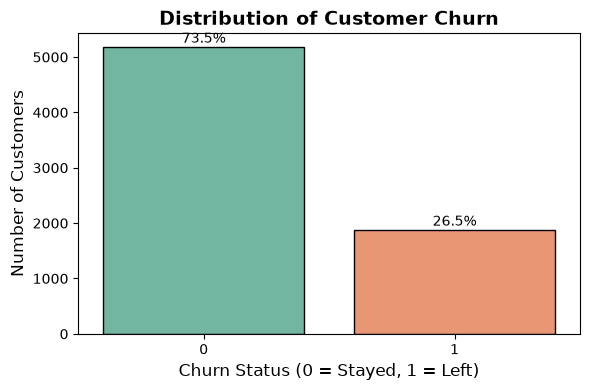

In [5]:
# Visualizing the Target Variable (Class Imbalance)
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='Set2', edgecolor='black')
plt.title('Distribution of Customer Churn', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status (0 = Stayed, 1 = Left)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

# Add percentage labels on top of the bars
total = len(df)
for p in plt.gca().patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    plt.annotate(percentage, (x, y), ha='center', va='center', fontsize=10)

plt.tight_layout()
plt.show()

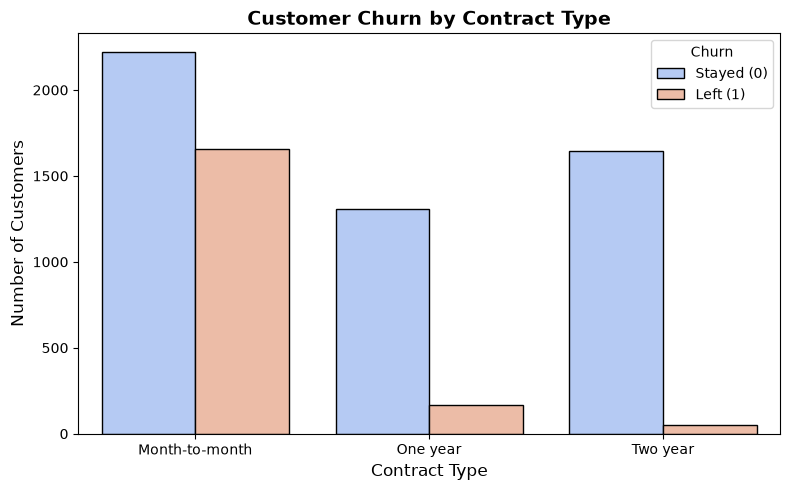

In [6]:
# Churn Rate by Contract Type (The most actionable insight)
plt.figure(figsize=(8, 5))
sns.countplot(x='Contract', hue='Churn', data=df, palette='coolwarm', edgecolor='black')
plt.title('Customer Churn by Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.legend(title='Churn', labels=['Stayed (0)', 'Left (1)'])
plt.tight_layout()
plt.show()

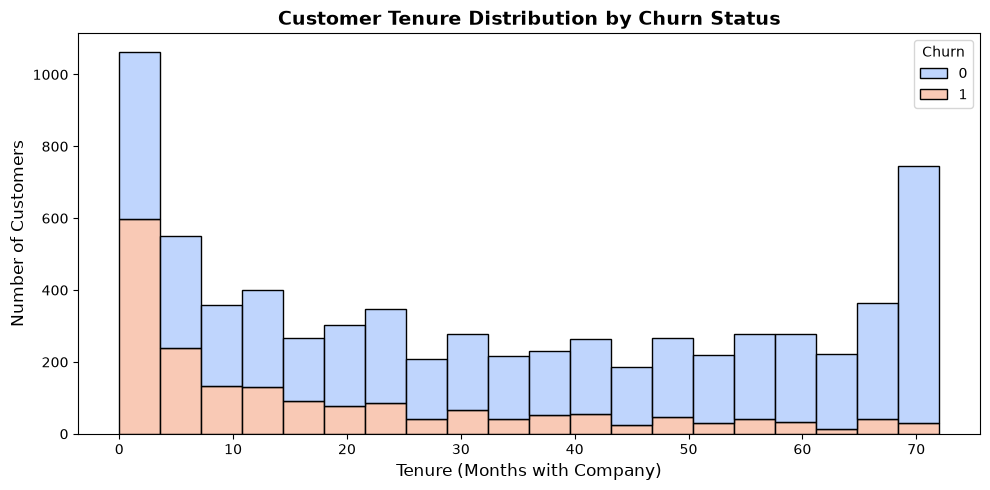

In [7]:
# Tenure Distribution (How long customers stay)
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=20, palette='coolwarm', edgecolor='black')
plt.title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Tenure (Months with Company)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.tight_layout()
plt.show()

## 5. Data Preprocessing & Train/Test Split

In [8]:
# Cell 7: Preparing Data for Machine Learning

# Keep all useful customer features
df_model = df.copy()

# Convert categorical columns into numerical format
df_encoded = pd.get_dummies(df_model, drop_first=True, dtype=int)

# Separate input features and target variable
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 30)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


## 6. Machine Learning Model Training & Evaluation

In [10]:
# Preparing Training and Testing Data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale the features for Logistic Regression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Data splitting and scaling completed successfully!")

Training data shape: (5634, 30)
Testing data shape: (1409, 30)
Data splitting and scaling completed successfully!


In [11]:
# Cell 8: Training the Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# --- MODEL 1: Logistic Regression (The Baseline) ---
# We use class_weight='balanced' because fewer people churn than stay.
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

# --- MODEL 2: Random Forest (The Advanced Model) ---
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_preds = rf_model.predict(X_test_scaled)

# --- EVALUATION ---
print("=== 1. LOGISTIC REGRESSION (Baseline) ===")
print(f"Accuracy: {accuracy_score(y_test, lr_preds):.4f}\n")
print(classification_report(y_test, lr_preds, target_names=['Stayed (0)', 'Churned (1)']))

print("=== 2. RANDOM FOREST (Advanced) ===")
print(f"Accuracy: {accuracy_score(y_test, rf_preds):.4f}\n")
print(classification_report(y_test, rf_preds, target_names=['Stayed (0)', 'Churned (1)']))

=== 1. LOGISTIC REGRESSION (Baseline) ===
Accuracy: 0.7388

              precision    recall  f1-score   support

  Stayed (0)       0.90      0.72      0.80      1035
 Churned (1)       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

=== 2. RANDOM FOREST (Advanced) ===
Accuracy: 0.7750

              precision    recall  f1-score   support

  Stayed (0)       0.86      0.82      0.84      1035
 Churned (1)       0.57      0.64      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.78      0.78      1409



## 7. Model Performance Visualization

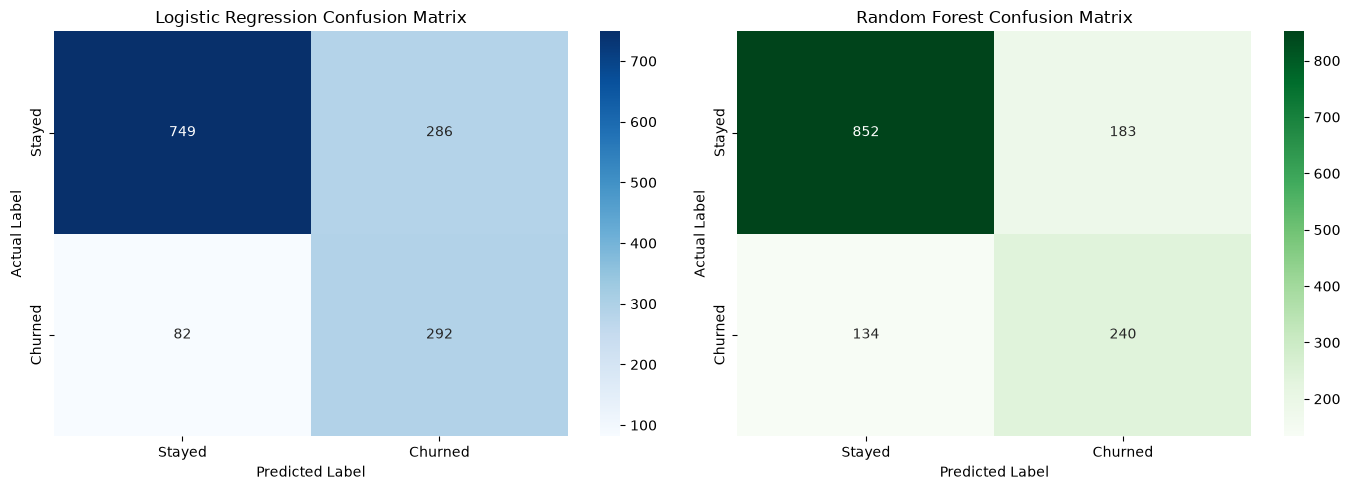

In [15]:
# Cell 9: Confusion Matrix Visualization

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression
cm_lr = confusion_matrix(y_test, lr_preds, labels=[0, 1])

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Stayed', 'Churned'],
            yticklabels=['Stayed', 'Churned'])

axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Random Forest
cm_rf = confusion_matrix(y_test, rf_preds, labels=[0, 1])

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Stayed', 'Churned'],
            yticklabels=['Stayed', 'Churned'])

axes[1].set_title('Random Forest Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

## Classification Reports

In [16]:
# Classification Reports

from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    lr_preds,
    labels=[0, 1],
    target_names=['Stayed', 'Churned']
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_preds,
    labels=[0, 1],
    target_names=['Stayed', 'Churned']
))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed       0.86      0.82      0.84      1035
     Churned       0.57      0.64      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.78      0.78      1409



## 8. Model Performance Comparison

In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Compare both models
results = []

for name, y_pred, y_prob in [
    ("Logistic Regression", lr_preds, lr_model.predict_proba(X_test_scaled)[:, 1]),
    ("Random Forest", rf_preds, rf_model.predict_proba(X_test)[:, 1])
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.round(3))

c:\Users\user\CHURN_PROJECT\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression     0.739      0.505   0.781     0.613    0.841
1        Random Forest     0.775      0.567   0.642     0.602    0.742


## ROC Curve Visualisation

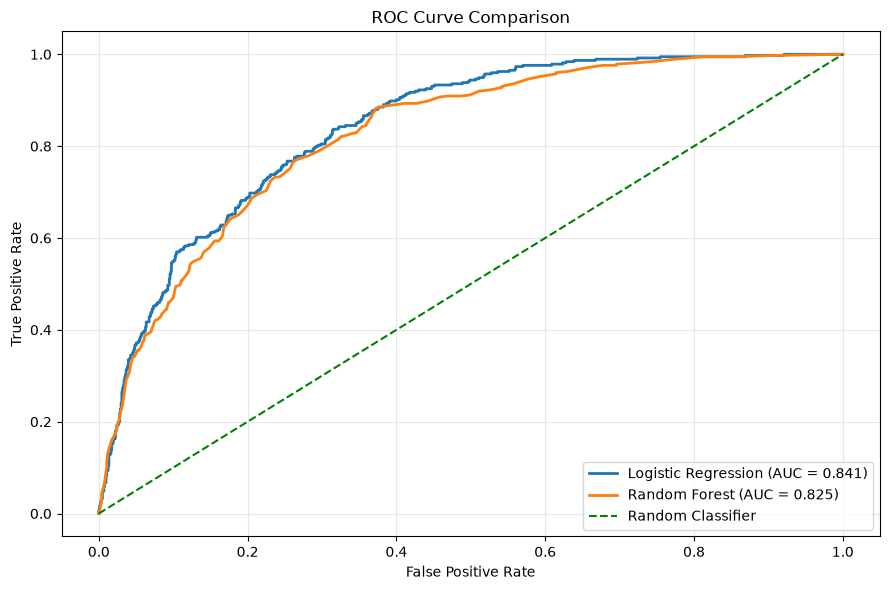

Logistic Regression AUC: 0.841
Random Forest AUC: 0.825


In [17]:
# Cell 10: ROC Curve Comparison

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# 1. Calculate predicted probabilities for both models
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

# 2. Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

# 3. Calculate AUC scores
lr_auc = auc(lr_fpr, lr_tpr)
rf_auc = auc(rf_fpr, rf_tpr)

# 4. Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(lr_fpr, lr_tpr,
         label=f'Logistic Regression (AUC = {lr_auc:.3f})',
         linewidth=2)

plt.plot(rf_fpr, rf_tpr,
         label=f'Random Forest (AUC = {rf_auc:.3f})',
         linewidth=2)

# Random classifier reference line
plt.plot([0, 1], [0, 1], 'g--',
         label='Random Classifier')

# 5. Graph formatting
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Display AUC scores
print("Logistic Regression AUC:", round(lr_auc, 3))
print("Random Forest AUC:", round(rf_auc, 3))



## 9. Feature Importance: What Drives Churn?

C:\Users\user\AppData\Local\Temp\ipykernel_7684\3929640510.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')


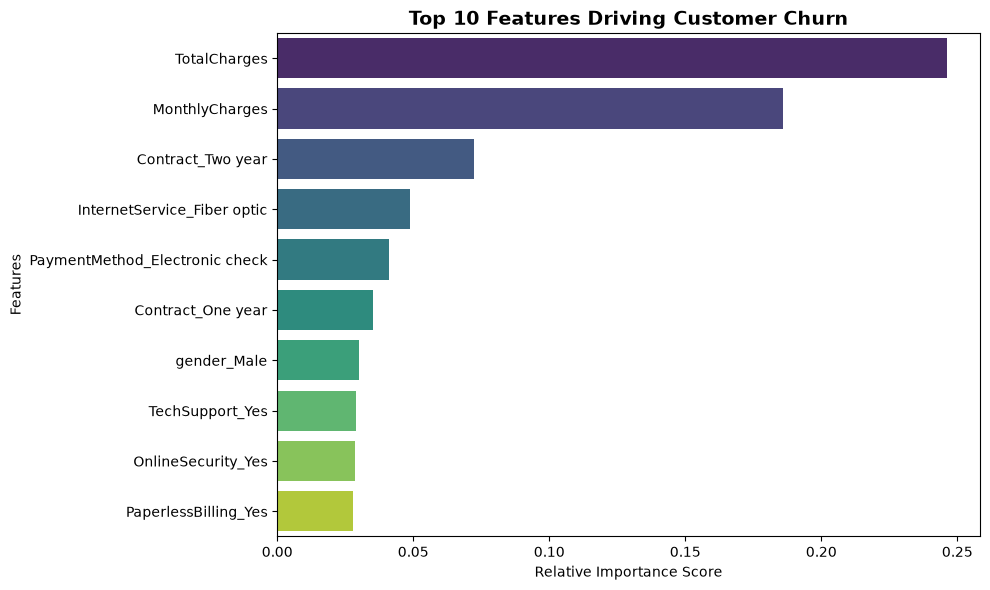

--- Top 5 Churn Drivers ---


,Feature,Importance
2,TotalCharges,0.246024
1,MonthlyCharges,0.185923
24,Contract_Two year,0.072288
9,InternetService_Fiber optic,0.048838
27,PaymentMethod_Electronic check,0.040985


In [ ]:
# Cell 10: Feature Importance from Random Forest

# 1. Extract the importance scores from the trained Random Forest model
importances = rf_model.feature_importances_

# 2. Create a DataFrame to match the importance scores with the actual column names
feature_names = X.columns
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# 3. Sort the features from most important to least important
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
plt.title('Top 10 Features Driving Customer Churn', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

print("--- Top 5 Churn Drivers ---")
display(feature_importance_df.head(5))

## 10. Dataset Quality & Security Check

In [18]:
# Cell 11: Dataset Quality Check

print("========== DATASET QUALITY CHECK ==========")

# 1. Dataset dimensions
print("\nDataset Shape:", df.shape)

# 2. Missing values
print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 3. Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Dataset information
print("\nDataset Information:")
df.info()

# 5. Target distribution
print("\nChurn Distribution:")
print(df['Churn'].value_counts())

# 6. Check customer ID
print("\nCustomer ID Present:", 'customerID' in df.columns)

# 7. Check tenure
print("\nTenure Present:", 'tenure' in df.columns)

========== DATASET QUALITY CHECK ==========

Dataset Shape: (7043, 20)

Missing Values:
Series([], dtype: int64)

Duplicate Rows: 22

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str  

## Duplicate Record Investigation

In [19]:
# Cell 12: Duplicate Record Investigation

# Display all duplicate records
duplicates = df[df.duplicated(keep=False)]

print("Total duplicate records:", len(duplicates))

print("\nDuplicate records preview:")
display(duplicates.head(10))

# Check whether duplicates have identical churn values
print("\nChurn distribution among duplicate records:")
print(duplicates['Churn'].value_counts())

# Check target distribution in the complete dataset
print("\nComplete dataset churn distribution:")
print(df['Churn'].value_counts())

print("\nTarget data type:")
print(df['Churn'].dtype)

Total duplicate records: 42

Duplicate records preview:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
22,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,1
100,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.20,0
542,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,0
646,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,1
662,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,0
690,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,0
964,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,1
976,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,1
1243,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,45.30,45.30,1
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,1



Churn distribution among duplicate records:
Churn
1    24
0    18
Name: count, dtype: int64

Complete dataset churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target data type:
int64


## 11. Final Data Preparation

In [20]:
# Cell 13: Final Data Preparation

import pandas as pd
import numpy as np

# Create a fresh copy
df_final = df.copy()

# Remove unnecessary customer ID if present
df_final.drop(columns=['customerID'], errors='ignore', inplace=True)

# Remove unnecessary spaces from categorical values
for col in df_final.select_dtypes(include=['object', 'str']).columns:
    df_final[col] = df_final[col].str.strip()

# Convert TotalCharges into numeric format
if 'TotalCharges' in df_final.columns:
    df_final['TotalCharges'] = pd.to_numeric(
        df_final['TotalCharges'], errors='coerce'
    )

# Separate features and target
X = df_final.drop('Churn', axis=1)
y = df_final['Churn'].astype(int)

print("Final Dataset Shape:", df_final.shape)
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMissing Values After Cleaning:")
print(df_final.isnull().sum()[df_final.isnull().sum() > 0])

print("\nTarget Distribution:")
print(y.value_counts())

Final Dataset Shape: (7043, 20)
Features Shape: (7043, 19)
Target Shape: (7043,)

Missing Values After Cleaning:
Series([], dtype: int64)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [21]:
# Cell 14: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Records: 5634
Testing Records: 1409

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing Target Distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [22]:
# Cell 15: Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer,
         make_column_selector(dtype_include=np.number)),

        ('cat', categorical_transformer,
         make_column_selector(dtype_include=['object', 'str']))
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


## Train Final ML Model

In [23]:
# Cell 16: Final Model Training Using Pipelines

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# MODEL 1: Logistic Regression
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# MODEL 2: Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42
    ))
])

# Train both models
print("Training Logistic Regression...")
lr_pipeline.fit(X_train, y_train)

print("Training Random Forest...")
rf_pipeline.fit(X_train, y_train)

print("\nBoth models trained successfully!")

# Generate predictions
lr_preds = lr_pipeline.predict(X_test)
rf_preds = rf_pipeline.predict(X_test)

print("\nPredictions generated successfully!")

Training Logistic Regression...
Training Random Forest...

Both models trained successfully!

Predictions generated successfully!


## Classification Reports

In [24]:
# Cell 17: Final Classification Reports

from sklearn.metrics import classification_report, accuracy_score

print("=" * 55)
print("LOGISTIC REGRESSION - FINAL RESULTS")
print("=" * 55)

print("Accuracy:", round(accuracy_score(y_test, lr_preds), 4))

print(classification_report(
    y_test,
    lr_preds,
    target_names=['Stayed', 'Churned']
))

print("=" * 55)
print("RANDOM FOREST - FINAL RESULTS")
print("=" * 55)

print("Accuracy:", round(accuracy_score(y_test, rf_preds), 4))

print(classification_report(
    y_test,
    rf_preds,
    target_names=['Stayed', 'Churned']
))

LOGISTIC REGRESSION - FINAL RESULTS
Accuracy: 0.7381
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

RANDOM FOREST - FINAL RESULTS
Accuracy: 0.7679
              precision    recall  f1-score   support

      Stayed       0.86      0.82      0.84      1035
     Churned       0.56      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409



## Final ROC Curve

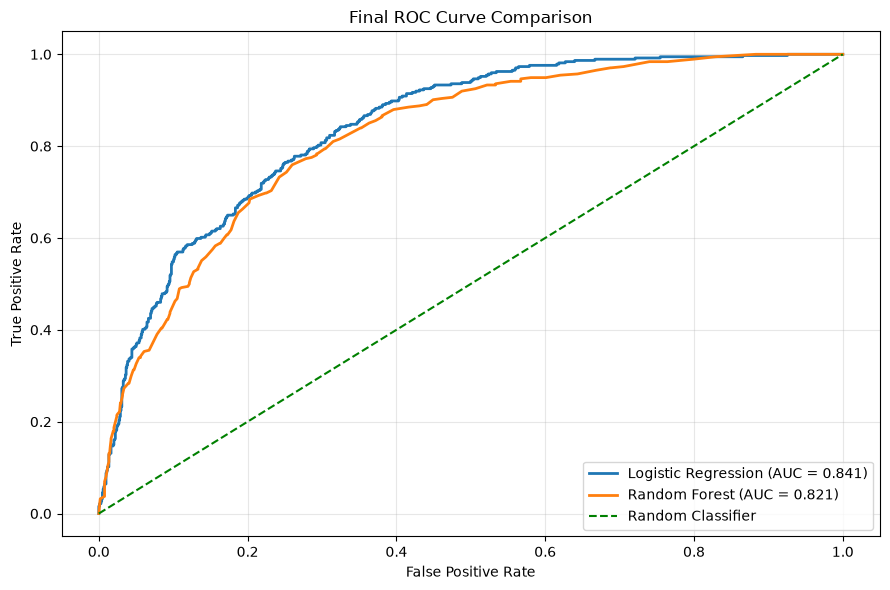

Logistic Regression AUC: 0.841
Random Forest AUC: 0.821


In [25]:
# Cell 18: Final ROC Curve Comparison

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Predicted probabilities
lr_probs = lr_pipeline.predict_proba(X_test)[:, 1]
rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]

# Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

# Calculate AUC
lr_auc = auc(lr_fpr, lr_tpr)
rf_auc = auc(rf_fpr, rf_tpr)

# Plot
plt.figure(figsize=(9, 6))

plt.plot(lr_fpr, lr_tpr,
         label=f'Logistic Regression (AUC = {lr_auc:.3f})',
         linewidth=2)

plt.plot(rf_fpr, rf_tpr,
         label=f'Random Forest (AUC = {rf_auc:.3f})',
         linewidth=2)

plt.plot([0, 1], [0, 1], 'g--',
         label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Final ROC Curve Comparison')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Logistic Regression AUC:", round(lr_auc, 3))
print("Random Forest AUC:", round(rf_auc, 3))

## Confusion Matrix

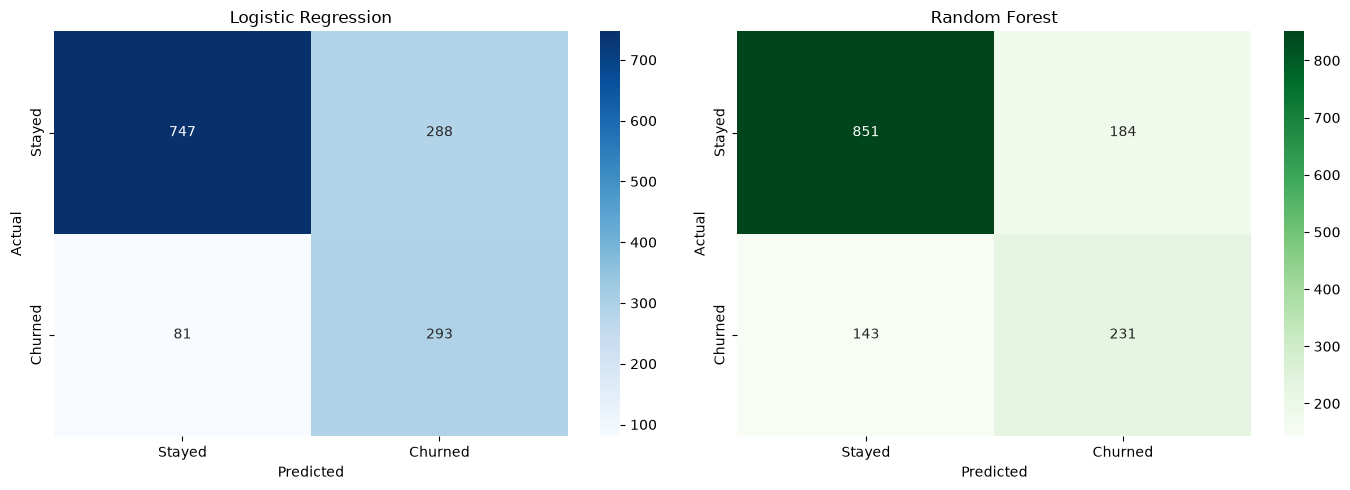

In [26]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression
cm_lr = confusion_matrix(y_test, lr_preds, labels=[0, 1])

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Random Forest
cm_rf = confusion_matrix(y_test, rf_preds, labels=[0, 1])

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1],
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Feature Importance(Logistic Regression)

TOP 15 FEATURES AFFECTING CUSTOMER CHURN


,Feature,Importance,Abs_Importance
1,num__tenure,-1.123595,1.123595
38,cat__Contract_Two year,-0.781255,0.781255
16,cat__InternetService_Fiber optic,0.705337,0.705337
2,num__MonthlyCharges,-0.663583,0.663583
36,cat__Contract_Month-to-month,0.663399,0.663399
15,cat__InternetService_DSL,-0.621009,0.621009
3,num__TotalCharges,0.457218,0.457218
35,cat__StreamingMovies_Yes,0.274978,0.274978
25,cat__DeviceProtection_No internet service,-0.274569,0.274569
17,cat__InternetService_No,-0.274569,0.274569


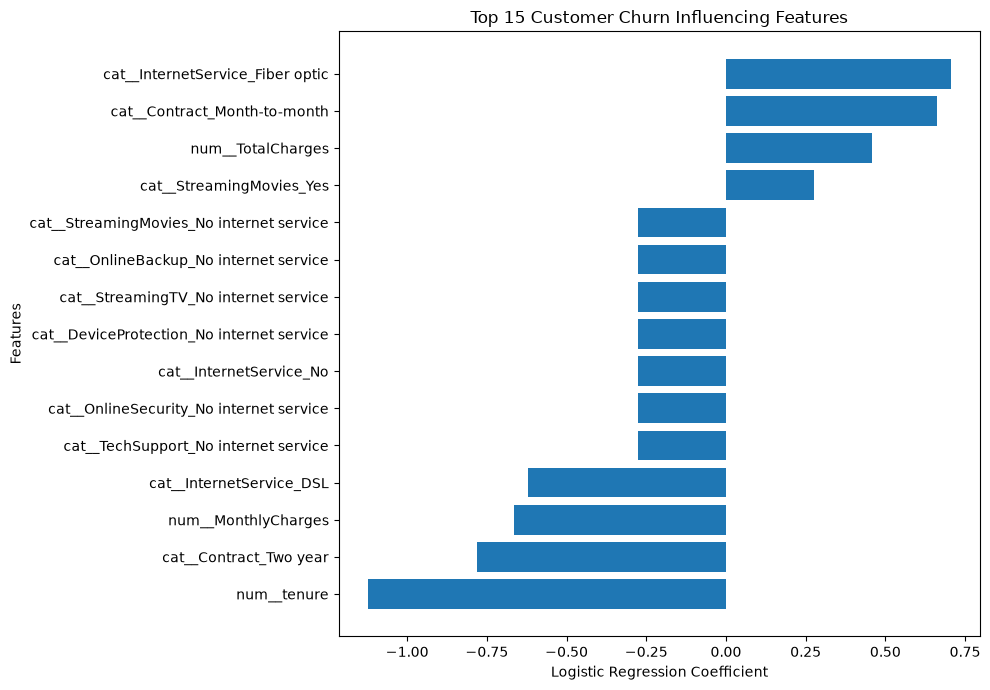

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Extract trained Logistic Regression model
lr_classifier = lr_pipeline.named_steps['classifier']

# Get feature names after preprocessing
feature_names = lr_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Get model coefficients
coefficients = lr_classifier.coef_[0]

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': coefficients
})

# Sort by absolute importance
feature_importance['Abs_Importance'] = abs(feature_importance['Importance'])

feature_importance = feature_importance.sort_values(
    by='Abs_Importance',
    ascending=False
)

# Display top 15 features
print("TOP 15 FEATURES AFFECTING CUSTOMER CHURN")
display(feature_importance.head(15))

# Visualize
top_features = feature_importance.head(15).sort_values('Importance')

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 15 Customer Churn Influencing Features')
plt.xlabel('Logistic Regression Coefficient')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## Feature Importance(Random Forest)

TOP 15 RANDOM FOREST FEATURES


,Feature,Importance
3,num__TotalCharges,0.143049
1,num__tenure,0.129100
2,num__MonthlyCharges,0.123688
36,cat__Contract_Month-to-month,0.066334
18,cat__OnlineSecurity_No,0.038803
38,cat__Contract_Two year,0.035268
43,cat__PaymentMethod_Electronic check,0.031222
16,cat__InternetService_Fiber optic,0.031023
27,cat__TechSupport_No,0.029433
21,cat__OnlineBackup_No,0.017067


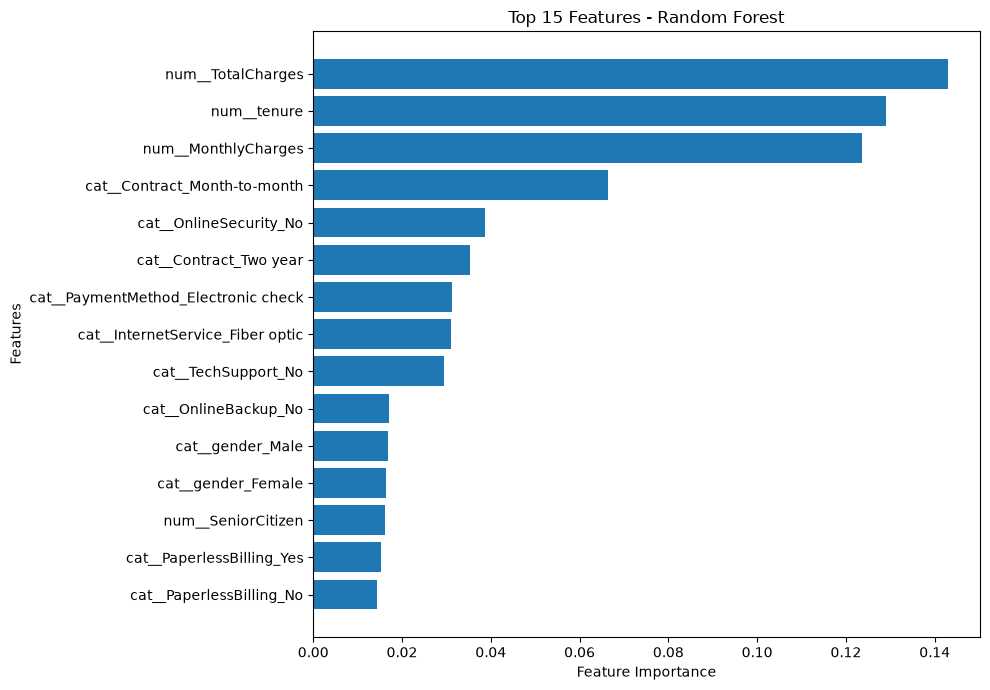

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract trained Random Forest model
rf_classifier = rf_pipeline.named_steps['classifier']

# Get feature names after preprocessing
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Extract feature importance
rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

# Sort features
rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print("TOP 15 RANDOM FOREST FEATURES")
display(rf_importance.head(15))

# Visualize
top_rf = rf_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_rf['Feature'],
    top_rf['Importance']
)

plt.title('Top 15 Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

## Logistic Regression Hyperparameter Tuning

In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Define parameters
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__solver': ['liblinear', 'lbfgs']
}

# Create Grid Search
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Train and tune
grid_search.fit(X_train, y_train)

# Display best parameters
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'classifier__C': 10, 'classifier__solver': 'liblinear'}
Best Cross-Validation ROC-AUC: 0.8455


In [30]:
# Get the best tuned model
best_lr_model = grid_search.best_estimator_

# Generate predictions
best_lr_preds = best_lr_model.predict(X_test)
best_lr_probs = best_lr_model.predict_proba(X_test)[:, 1]

# Evaluate performance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

print("TUNED LOGISTIC REGRESSION RESULTS")
print("=" * 50)

print("Accuracy:", round(
    accuracy_score(y_test, best_lr_preds), 4
))

print("\nROC-AUC:", round(
    roc_auc_score(y_test, best_lr_probs), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_lr_preds,
    target_names=['Stayed', 'Churned']
))

TUNED LOGISTIC REGRESSION RESULTS
Accuracy: 0.7395

ROC-AUC: 0.8406

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## Random Forest Hyperparameter Tuning

In [31]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("Starting Random Forest Hyperparameter Tuning...")

rf_grid_search.fit(X_train, y_train)

print("\nBest Random Forest Parameters:")
print(rf_grid_search.best_params_)

print(
    "\nBest Cross-Validation ROC-AUC:",
    round(rf_grid_search.best_score_, 4)
)

Starting Random Forest Hyperparameter Tuning...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Random Forest Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best Cross-Validation ROC-AUC: 0.8456


In [32]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

# Get best tuned Random Forest
best_rf_model = rf_grid_search.best_estimator_

# Generate predictions
best_rf_preds = best_rf_model.predict(X_test)
best_rf_probs = best_rf_model.predict_proba(X_test)[:, 1]

# Evaluate model
print("TUNED RANDOM FOREST RESULTS")
print("=" * 50)

print("Accuracy:", round(
    accuracy_score(y_test, best_rf_preds), 4
))

print("\nROC-AUC:", round(
    roc_auc_score(y_test, best_rf_probs), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_rf_preds,
    target_names=['Stayed', 'Churned']
))

TUNED RANDOM FOREST RESULTS
Accuracy: 0.7573

ROC-AUC: 0.8388

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.75      0.82      1035
     Churned       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



## Final Model Comparison

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    'Original Logistic Regression': (lr_pipeline, lr_preds),
    'Tuned Logistic Regression': (best_lr_model, best_lr_preds),
    'Original Random Forest': (rf_pipeline, rf_preds),
    'Tuned Random Forest': (best_rf_model, best_rf_preds)
}

comparison = []

for name, (model, predictions) in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    comparison.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Churn Precision': precision_score(y_test, predictions),
        'Churn Recall': recall_score(y_test, predictions),
        'Churn F1-Score': f1_score(y_test, predictions),
        'ROC-AUC': roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(comparison)

print("FINAL MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-Score,ROC-AUC
0,Original Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
1,Tuned Logistic Regression,0.7395,0.5060,0.7834,0.6149,0.8406
2,Original Random Forest,0.7679,0.5566,0.6176,0.5856,0.8208
3,Tuned Random Forest,0.7573,0.5292,0.7754,0.6291,0.8388


## Prediction Threshold Analysis

In [34]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Get predicted probabilities
lr_probabilities = lr_pipeline.predict_proba(X_test)[:, 1]

# Test different thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    predictions = (lr_probabilities >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1-Score': f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

print("LOGISTIC REGRESSION - THRESHOLD COMPARISON")

display(threshold_df.round(4))

LOGISTIC REGRESSION - THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.30,0.6529,0.4289,0.9278,0.5866
1,0.35,0.6785,0.4478,0.9064,0.5995
2,0.40,0.7012,0.4662,0.8663,0.6062
3,0.45,0.7189,0.4830,0.8369,0.6125
4,0.50,0.7381,0.5043,0.7834,0.6136
5,0.55,0.7530,0.5243,0.7513,0.6176
6,0.60,0.7622,0.5399,0.7059,0.6118


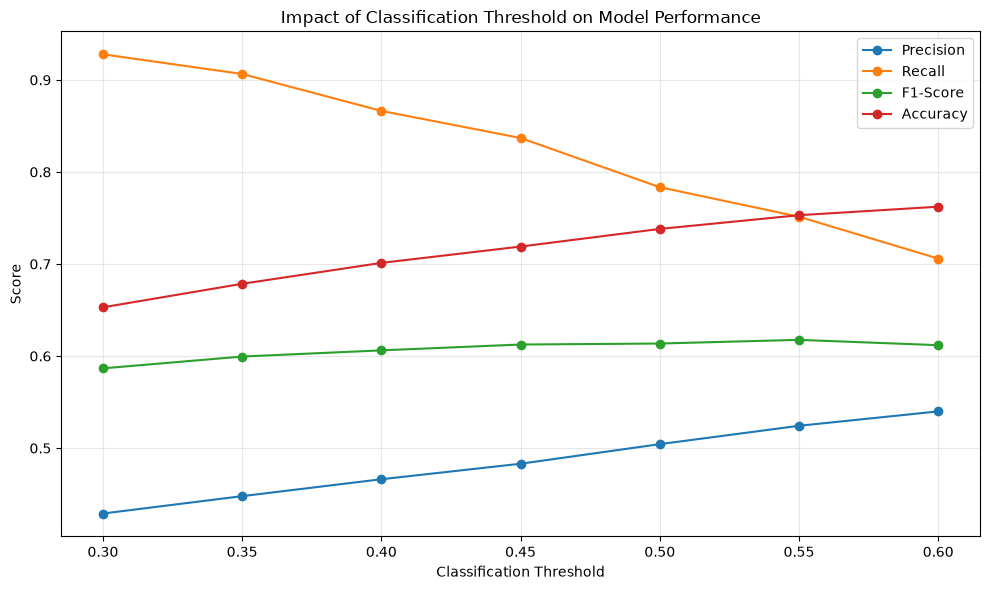

In [35]:
#THRESHOLD PERFORMANCE EVALUATION
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(threshold_df['Threshold'], threshold_df['Precision'],
         marker='o', label='Precision')

plt.plot(threshold_df['Threshold'], threshold_df['Recall'],
         marker='o', label='Recall')

plt.plot(threshold_df['Threshold'], threshold_df['F1-Score'],
         marker='o', label='F1-Score')

plt.plot(threshold_df['Threshold'], threshold_df['Accuracy'],
         marker='o', label='Accuracy')

plt.title('Impact of Classification Threshold on Model Performance')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.xticks(threshold_df['Threshold'])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
#Threshold Selection Using Cross-Validation
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd

# 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Generate out-of-fold probabilities using training data
print("Generating Logistic Regression predictions...")

lr_oof_probs = cross_val_predict(
    best_lr_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

print("Generating Random Forest predictions...")

rf_oof_probs = cross_val_predict(
    best_rf_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# Compare thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for model_name, probabilities in [
    ('Tuned Logistic Regression', lr_oof_probs),
    ('Tuned Random Forest', rf_oof_probs)
]:
    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(y_train, predictions),
            'Precision': precision_score(y_train, predictions),
            'Recall': recall_score(y_train, predictions),
            'F1-Score': f1_score(y_train, predictions)
        })

cv_threshold_df = pd.DataFrame(results)

display(cv_threshold_df.round(4))

Generating Logistic Regression predictions...
Generating Random Forest predictions...


,Model,Threshold,Accuracy,Precision,Recall,F1-Score
0,Tuned Logistic Regression,0.30,0.6466,0.4240,0.9258,0.5816
1,Tuned Logistic Regression,0.35,0.6780,0.4471,0.9023,0.5980
2,Tuned Logistic Regression,0.40,0.7048,0.4696,0.8682,0.6095
3,Tuned Logistic Regression,0.45,0.7267,0.4911,0.8328,0.6179
4,Tuned Logistic Regression,0.50,0.7481,0.5164,0.8000,0.6277
5,Tuned Logistic Regression,0.55,0.7655,0.5411,0.7659,0.6342
6,Tuned Logistic Regression,0.60,0.7820,0.5709,0.7191,0.6365
7,Tuned Random Forest,0.30,0.6700,0.4402,0.8963,0.5904
8,Tuned Random Forest,0.35,0.7025,0.4675,0.8716,0.6086
9,Tuned Random Forest,0.40,0.7251,0.4895,0.8388,0.6182


## Final Model Selection

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Select final model and threshold
final_model = best_lr_model
final_threshold = 0.60

# Generate probabilities on untouched test data
final_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
final_predictions = (
    final_probabilities >= final_threshold
).astype(int)

# Evaluate final model
print("FINAL MODEL: TUNED LOGISTIC REGRESSION")
print("Classification Threshold:", final_threshold)

print("\nAccuracy:", round(
    accuracy_score(y_test, final_predictions), 4
))

print("Precision:", round(
    precision_score(y_test, final_predictions), 4
))

print("Recall:", round(
    recall_score(y_test, final_predictions), 4
))

print("F1-Score:", round(
    f1_score(y_test, final_predictions), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, final_probabilities), 4
))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=['Stayed', 'Churned']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

FINAL MODEL: TUNED LOGISTIC REGRESSION
Classification Threshold: 0.6

Accuracy: 0.763
Precision: 0.5408
Recall: 0.7086
F1-Score: 0.6134
ROC-AUC: 0.8406

Detailed Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.78      0.83      1035
     Churned       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409


Confusion Matrix:
[[810 225]
 [109 265]]


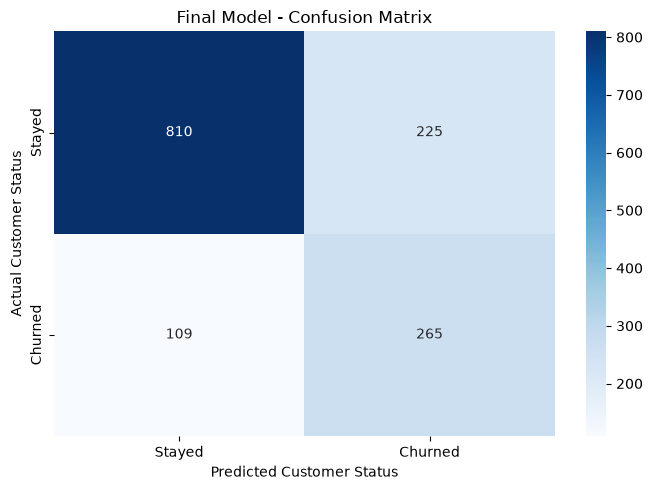

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title('Final Model - Confusion Matrix')
plt.xlabel('Predicted Customer Status')
plt.ylabel('Actual Customer Status')

plt.tight_layout()
plt.show()

## Saving Final ML Model

In [ ]:
import joblib
import os

# Create a folder for saved models
os.makedirs("models", exist_ok=True)

# Save the complete trained pipeline
joblib.dump(
    final_model,
    "models/telecom_churn_model.pkl"
)

# Save the selected classification threshold
joblib.dump(
    final_threshold,
    "models/churn_threshold.pkl"
)

print("Final model saved successfully!")
print("Model location: models/telecom_churn_model.pkl")
print("Threshold saved:", final_threshold)